# ***Well Log Analysis — Exploratory Data Analysis***
## ***FORCE 2020 Lithofacies Prediction Dataset***
Exploring log curve distributions, well coverage, lithology class balance,
and data quality before any preprocessing or modelling.

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

# Paths
DATA_PATH    = "C:/Users/user/Desktop/SK/Data Science/Personal Projects/Well-Log-Analysis/data/raw"
FIGURES_PATH = "C:/Users/user/Desktop/SK/Data Science/Personal Projects/Well-Log-Analysis/outputs/figures"
os.makedirs(FIGURES_PATH, exist_ok=True)

# Plot defaults
plt.rcParams['figure.dpi']    = 120
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.labelsize'] = 9

print("Ready.")

Ready.


### ***Load the data***

In [2]:
df = pd.read_csv(
    os.path.join(DATA_PATH, "CSV_train.csv"),
    sep=';'
)

print(f"Shape         : {df.shape}")
print(f"Rows          : {df.shape[0]:,}")
print(f"Columns       : {df.shape[1]}")
print(f"\nColumn names:")
for col in df.columns:
    print(f"  {col}")

Shape         : (1170511, 29)
Rows          : 1,170,511
Columns       : 29

Column names:
  WELL
  DEPTH_MD
  X_LOC
  Y_LOC
  Z_LOC
  GROUP
  FORMATION
  CALI
  RSHA
  RMED
  RDEP
  RHOB
  GR
  SGR
  NPHI
  PEF
  DTC
  SP
  BS
  ROP
  DTS
  DCAL
  DRHO
  MUDWEIGHT
  RMIC
  ROPA
  RXO
  FORCE_2020_LITHOFACIES_LITHOLOGY
  FORCE_2020_LITHOFACIES_CONFIDENCE


# ***Understanding what each column is***

In [3]:
print("Column types and non-null counts:\n")
print(df.info())
print(f"\nFirst 5 rows:")
df.head()

Column types and non-null counts:

<class 'pandas.DataFrame'>
RangeIndex: 1170511 entries, 0 to 1170510
Data columns (total 29 columns):
 #   Column                             Non-Null Count    Dtype  
---  ------                             --------------    -----  
 0   WELL                               1170511 non-null  str    
 1   DEPTH_MD                           1170511 non-null  float64
 2   X_LOC                              1159736 non-null  float64
 3   Y_LOC                              1159736 non-null  float64
 4   Z_LOC                              1159736 non-null  float64
 5   GROUP                              1169233 non-null  str    
 6   FORMATION                          1033517 non-null  str    
 7   CALI                               1082634 non-null  float64
 8   RSHA                               630650 non-null   float64
 9   RMED                               1131518 non-null  float64
 10  RDEP                               1159496 non-null  float64
 11  

,WELL,DEPTH_MD,X_LOC,Y_LOC,Z_LOC,GROUP,FORMATION,CALI,RSHA,RMED,...,ROP,DTS,DCAL,DRHO,MUDWEIGHT,RMIC,ROPA,RXO,FORCE_2020_LITHOFACIES_LITHOLOGY,FORCE_2020_LITHOFACIES_CONFIDENCE
0,15/9-13,494.528,437641.96875,6470972.5,-469.501831,NORDLAND GP.,NaN,19.480835,NaN,1.611410,...,34.636410,NaN,NaN,-0.574928,NaN,NaN,NaN,NaN,65000,1.0
1,15/9-13,494.680,437641.96875,6470972.5,-469.653809,NORDLAND GP.,NaN,19.468800,NaN,1.618070,...,34.636410,NaN,NaN,-0.570188,NaN,NaN,NaN,NaN,65000,1.0
2,15/9-13,494.832,437641.96875,6470972.5,-469.805786,NORDLAND GP.,NaN,19.468800,NaN,1.626459,...,34.779556,NaN,NaN,-0.574245,NaN,NaN,NaN,NaN,65000,1.0
3,15/9-13,494.984,437641.96875,6470972.5,-469.957794,NORDLAND GP.,NaN,19.459282,NaN,1.621594,...,39.965164,NaN,NaN,-0.586315,NaN,NaN,NaN,NaN,65000,1.0
4,15/9-13,495.136,437641.96875,6470972.5,-470.109772,NORDLAND GP.,NaN,19.453100,NaN,1.602679,...,57.483765,NaN,NaN,-0.597914,NaN,NaN,NaN,NaN,65000,1.0


### ***How many wells do we have?***

In [4]:
wells = df['WELL'].unique()
print(f"Number of wells : {len(wells)}")
print(f"\nWell names:")
for w in sorted(wells):
    n_rows = len(df[df['WELL'] == w])
    print(f"  {w:<25} {n_rows:>7,} depth samples")

Number of wells : 98

Well names:
  15/9-13                    18,270 depth samples
  15/9-15                    17,717 depth samples
  15/9-17                    17,350 depth samples
  16/1-2                      1,734 depth samples
  16/1-6 A                    3,623 depth samples
  16/10-1                    17,675 depth samples
  16/10-2                     2,437 depth samples
  16/10-3                    15,956 depth samples
  16/10-5                     2,765 depth samples
  16/11-1 ST3                14,938 depth samples
  16/2-11 A                  10,708 depth samples
  16/2-16                    10,025 depth samples
  16/2-6                      9,138 depth samples
  16/4-1                     14,082 depth samples
  16/5-3                      3,021 depth samples
  16/7-4                     10,010 depth samples
  16/7-5                     15,590 depth samples
  16/8-1                      6,685 depth samples
  17/11-1                    20,099 depth samples
  25/11-15      

Each well is a separate borehole. More wells means the model has seen more geological variety — different fields, different depths, different rock sequences. I'll train on most wells and hold one or two out as a test set, which is the geologically correct way to validate a well log model.

### ***Depth coverage per well***

In [5]:
print("Depth range per well:\n")
print(f"  {'Well':<25} {'Min depth':>12}  {'Max depth':>12}  {'Interval':>10}")
print("  " + "-"*64)

for w in sorted(wells):
    sub  = df[df['WELL'] == w]['DEPTH_MD']
    mn   = sub.min()
    mx   = sub.max()
    rng  = mx - mn
    print(f"  {w:<25} {mn:>12.1f}  {mx:>12.1f}  {rng:>10.1f} m")

Depth range per well:

  Well                         Min depth     Max depth    Interval
  ----------------------------------------------------------------
  15/9-13                          494.5        3272.0      2777.5 m
  15/9-15                          485.3        3200.1      2714.9 m
  15/9-17                          472.4        3114.5      2642.1 m
  16/1-2                          2645.6        2909.0       263.4 m
  16/1-6 A                        1176.0        1726.5       550.5 m
  16/10-1                          439.4        3125.9      2686.4 m
  16/10-2                         2767.3        3137.5       370.3 m
  16/10-3                          415.3        2840.4      2425.2 m
  16/10-5                         2607.0        3027.1       420.1 m
  16/11-1 ST3                      682.9        2953.3      2270.4 m
  16/2-11 A                        734.4        2361.9      1627.5 m
  16/2-16                          684.3        2207.9      1523.6 m
  16/2-6       

This tells you how deep each well goes. Wells with very different depth ranges may be sampling completely different geological sections — important context when interpreting model performance.

### ***The lithology target column***

In [6]:
# The lithology label column
LITHOLOGY_COL = 'FORCE_2020_LITHOFACIES_LITHOLOGY'

# Map numeric codes to readable names
LITHOLOGY_KEYS = {
    30000: 'Sandstone',
    65030: 'Sandstone/Shale',
    65000: 'Shale',
    80000: 'Marl',
    74000: 'Dolomite',
    70000: 'Limestone',
    70032: 'Chalk',
    88000: 'Halite',
    86000: 'Anhydrite',
    99000: 'Tuff',
    90000: 'Coal',
    93000: 'Basement',
}

LITHOLOGY_COLORS = {
    'Sandstone':       '#FFFF00',
    'Sandstone/Shale': '#FFE033',
    'Shale':           '#808080',
    'Marl':            '#97C459',
    'Dolomite':        '#7F77DD',
    'Limestone':       '#4466FF',
    'Chalk':           '#FFFFFF',
    'Halite':          '#FF44CC',
    'Anhydrite':       '#FF4444',
    'Tuff':            '#44CCFF',
    'Coal':            '#222222',
    'Basement':        '#8B4513',
}

# Add readable name column
df['LITHOLOGY_NAME'] = df[LITHOLOGY_COL].map(LITHOLOGY_KEYS)

# Class distribution
print("Lithology class distribution:\n")
counts = df['LITHOLOGY_NAME'].value_counts()
total  = len(df)

print(f"  {'Class':<20}  {'Count':>10}  {'Percent':>8}")
print("  " + "-"*44)
for name, cnt in counts.items():
    pct = 100 * cnt / total
    bar = '█' * int(pct / 2)
    print(f"  {name:<20}  {cnt:>10,}  {pct:>7.1f}%  {bar}")

Lithology class distribution:

  Class                      Count   Percent
  --------------------------------------------
  Shale                    720,803     61.6%  ██████████████████████████████
  Sandstone                168,937     14.4%  ███████
  Sandstone/Shale          150,455     12.9%  ██████
  Limestone                 56,320      4.8%  ██
  Marl                      33,329      2.8%  █
  Tuff                      15,245      1.3%  
  Chalk                     10,513      0.9%  
  Halite                     8,213      0.7%  
  Coal                       3,820      0.3%  
  Dolomite                   1,688      0.1%  
  Anhydrite                  1,085      0.1%  
  Basement                     103      0.0%  


Shale at 61.6% is the dominant class — exactly as expected for a North Sea dataset. The bottom four classes are extremely rare:

| Class | Count | Risk |
|---|---|---|
| Coal | 3,820 | 0.3% — very few samples |
| Dolomite | 1,688 | 0.1% — dangerously few |
| Anhydrite | 1,085 | 0.1% — dangerously few |
| Basement | 103 | 0.01% — essentially absent |

Basement has only 103 samples across the entire dataset. That is not enough to train a reliable classifier. We will need to make a decision about these ultra-rare classes in Phase 3.



### ***Missing data analysis***

In [7]:
# Log curve columns — everything except metadata and target
META_COLS   = ['WELL', 'DEPTH_MD', 'GROUP', 'FORMATION',
               'X_LOC', 'Y_LOC', 'Z_LOC', LITHOLOGY_COL, 'LITHOLOGY_NAME']
LOG_COLS    = [c for c in df.columns if c not in META_COLS]

print(f"Log curve columns ({len(LOG_COLS)} total):\n")
print(f"  {'Column':<12}  {'Non-null':>10}  {'Missing':>10}  {'% Missing':>10}")
print("  " + "-"*48)

for col in LOG_COLS:
    non_null = df[col].notna().sum()
    missing  = df[col].isna().sum()
    pct      = 100 * missing / len(df)
    flag     = " ← heavy missing" if pct > 50 else ""
    print(f"  {col:<12}  {non_null:>10,}  {missing:>10,}  {pct:>9.1f}%{flag}")

Log curve columns (21 total):

  Column          Non-null     Missing   % Missing
  ------------------------------------------------
  CALI           1,082,634      87,877        7.5%
  RSHA             630,650     539,861       46.1%
  RMED           1,131,518      38,993        3.3%
  RDEP           1,159,496      11,015        0.9%
  RHOB           1,009,242     161,269       13.8%
  GR             1,170,511           0        0.0%
  SGR               69,353   1,101,158       94.1% ← heavy missing
  NPHI             765,409     405,102       34.6%
  PEF              671,692     498,819       42.6%
  DTC            1,089,648      80,863        6.9%
  SP               864,247     306,264       26.2%
  BS               682,657     487,854       41.7%
  ROP              535,071     635,440       54.3% ← heavy missing
  DTS              174,613     995,898       85.1% ← heavy missing
  DCAL             298,833     871,678       74.5% ← heavy missing
  DRHO             987,857     182,654

This is the most important output. Five logs have catastrophic missingness:

| Log | Missing | Decision |
|---|---|---|
| SGR | 94.1% | Drop entirely |
| RMIC | 85.0% | Drop entirely |
| DTS | 85.1% | Drop entirely |
| ROPA | 83.6% | Drop entirely |
| DCAL | 74.5% | Drop entirely |
| MUDWEIGHT | 73.0% | Drop entirely |
| RXO | 72.0% | Drop entirely |

Any log missing more than 70% of values across the dataset is not a reliable predictor. We drop those entirely. The logs we keep and work with are:

**Keep:** GR (0% missing — perfect), RDEP (0.9%), RMED (3.3%), DTC (6.9%), CALI (7.5%), RHOB (13.8%), DRHO (15.6%), SP (26.2%), NPHI (34.6%), PEF (42.6%), BS (41.7%), RSHA (46.1%)

For the kept logs with moderate missingness (NPHI at 34.6%, PEF at 42.6%) we will impute using the median value per well — not the global median, because log values vary significantly between wells.

### ***Log curve statistics***

In [8]:
print("Log curve statistics:\n")
df[LOG_COLS].describe().round(3)

Log curve statistics:



,CALI,RSHA,RMED,RDEP,RHOB,GR,SGR,NPHI,PEF,DTC,...,BS,ROP,DTS,DCAL,DRHO,MUDWEIGHT,RMIC,ROPA,RXO,FORCE_2020_LITHOFACIES_CONFIDENCE
count,1082634.000,630650.000,1131518.000,1159496.000,1009242.000,1170511.000,69353.000,765409.000,671692.000,1089648.000,...,682657.000,535071.000,174613.000,298833.000,987857.000,316151.000,176160.000,192325.000,327427.000,1170332.000
mean,13.186,10.695,4.987,10.691,2.285,70.914,64.896,0.332,6.320,113.358,...,11.931,137.368,204.655,1.224,0.012,1.216,7.797,23.505,-95.779,1.164
std,3.799,100.643,54.673,113.948,0.253,34.231,38.436,0.130,10.955,29.990,...,3.330,1539.384,71.068,54.373,7.478,10.181,89.742,22.633,348.980,0.445
min,2.344,0.000,-0.008,0.032,0.721,0.109,-777.986,-0.036,0.100,7.415,...,6.000,-0.118,69.163,-12.215,-7429.339,0.126,0.057,-999.250,-999.900,1.000
25%,9.430,0.854,0.914,0.910,2.092,47.627,42.962,0.241,3.414,87.826,...,8.500,5.628,155.937,0.148,-0.009,0.144,0.891,11.282,0.688,1.000
50%,12.556,1.399,1.444,1.439,2.321,68.368,69.563,0.327,4.314,109.585,...,12.250,17.800,188.201,0.557,0.002,0.156,1.967,20.131,1.367,1.000
75%,16.711,3.099,2.681,2.557,2.489,89.036,87.910,0.423,5.969,140.774,...,12.250,34.813,224.645,1.300,0.022,1.168,5.085,31.138,3.421,1.000
max,28.279,2193.905,1988.616,1999.887,3.458,1076.964,963.609,1.000,383.130,320.479,...,26.000,47015.125,676.578,10011.423,2.837,185.731,10000.000,742.798,35930.672,3.000


### ***Visualise log curve distributions***

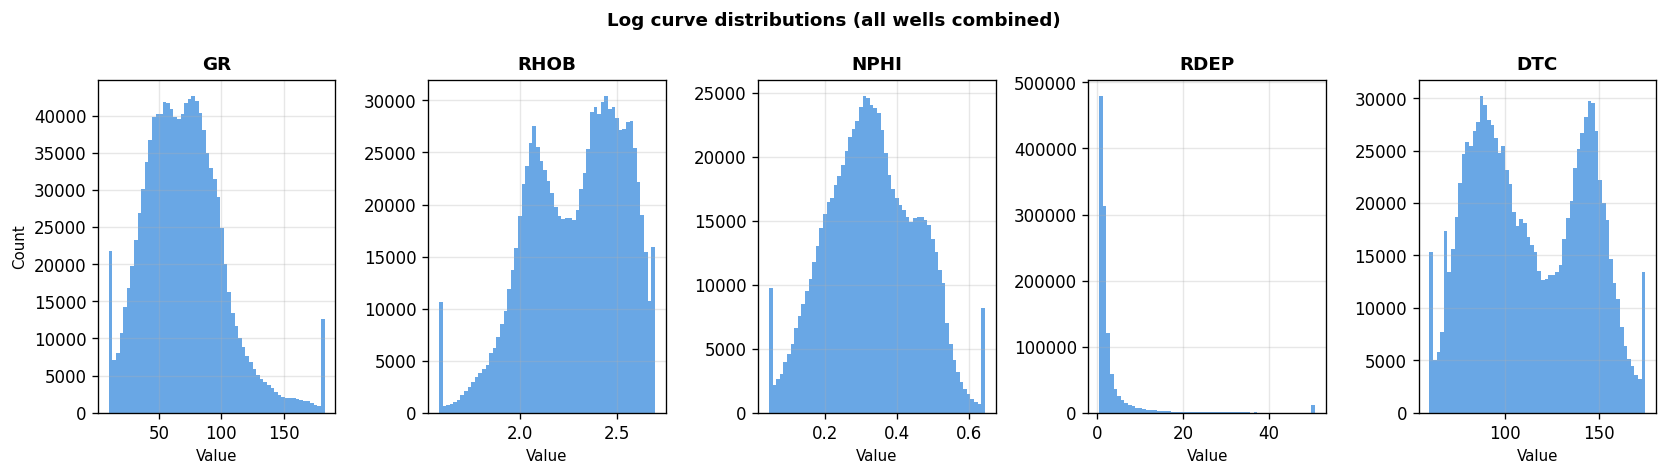

Saved → outputs/figures/log_distributions.png


In [9]:
# Choose the most important curves for initial inspection
KEY_LOGS = ['GR', 'RHOB', 'NPHI', 'RDEP', 'DTC']
KEY_LOGS = [c for c in KEY_LOGS if c in df.columns]

fig, axes = plt.subplots(1, len(KEY_LOGS), figsize=(14, 4))
fig.suptitle("Log curve distributions (all wells combined)",
             fontsize=11, fontweight='bold')

for ax, col in zip(axes, KEY_LOGS):
    data = df[col].dropna()
    # Clip extreme values for cleaner visualisation
    p1, p99 = data.quantile(0.01), data.quantile(0.99)
    data_clipped = data.clip(p1, p99)

    ax.hist(data_clipped, bins=60, color='#378ADD',
            alpha=0.75, edgecolor='none')
    ax.set_title(col, fontweight='bold')
    ax.set_xlabel("Value")
    ax.set_ylabel("Count" if col == KEY_LOGS[0] else "")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, "log_distributions.png"),
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved → outputs/figures/log_distributions.png")

### ***Class distribution bar chart***

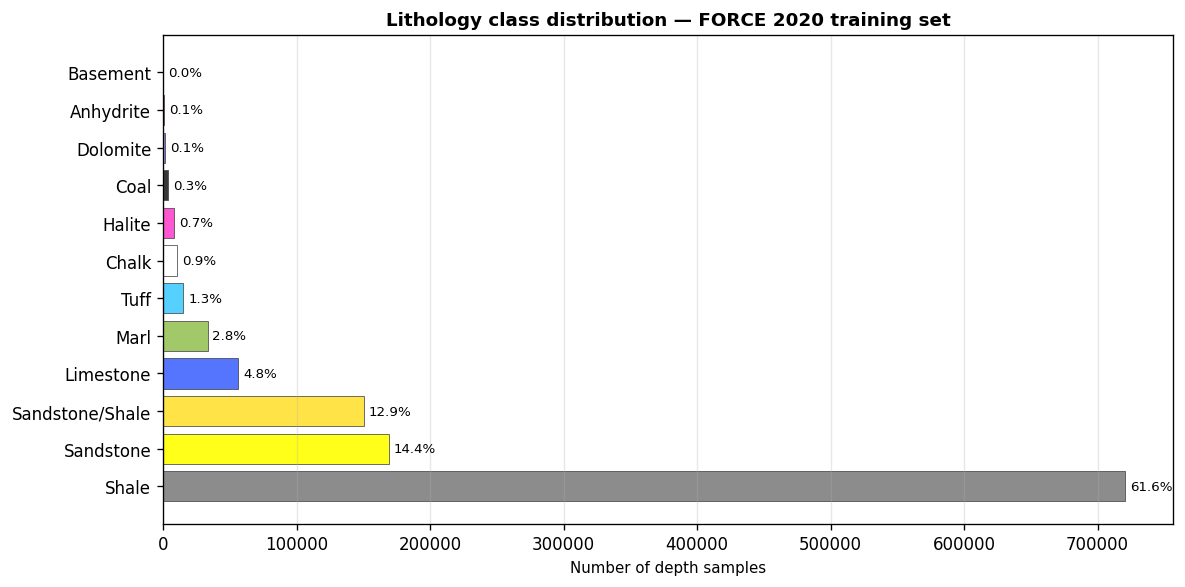

Saved → outputs/figures/lithology_distribution.png


In [10]:
fig, ax = plt.subplots(figsize=(10, 5))

colors = [LITHOLOGY_COLORS.get(name, '#888888')
          for name in counts.index]

bars = ax.barh(counts.index, counts.values,
               color=colors, edgecolor='#444444',
               linewidth=0.5, alpha=0.9)

ax.set_xlabel("Number of depth samples")
ax.set_title("Lithology class distribution — FORCE 2020 training set",
             fontsize=11, fontweight='bold')
ax.grid(True, axis='x', alpha=0.3)

# Add percentage labels
for bar, (name, cnt) in zip(bars, counts.items()):
    pct = 100 * cnt / total
    ax.text(bar.get_width() + total * 0.003,
            bar.get_y() + bar.get_height() / 2,
            f'{pct:.1f}%', va='center', fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, "lithology_distribution.png"),
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved → outputs/figures/lithology_distribution.png")

#### ***Well log track plot for one well***


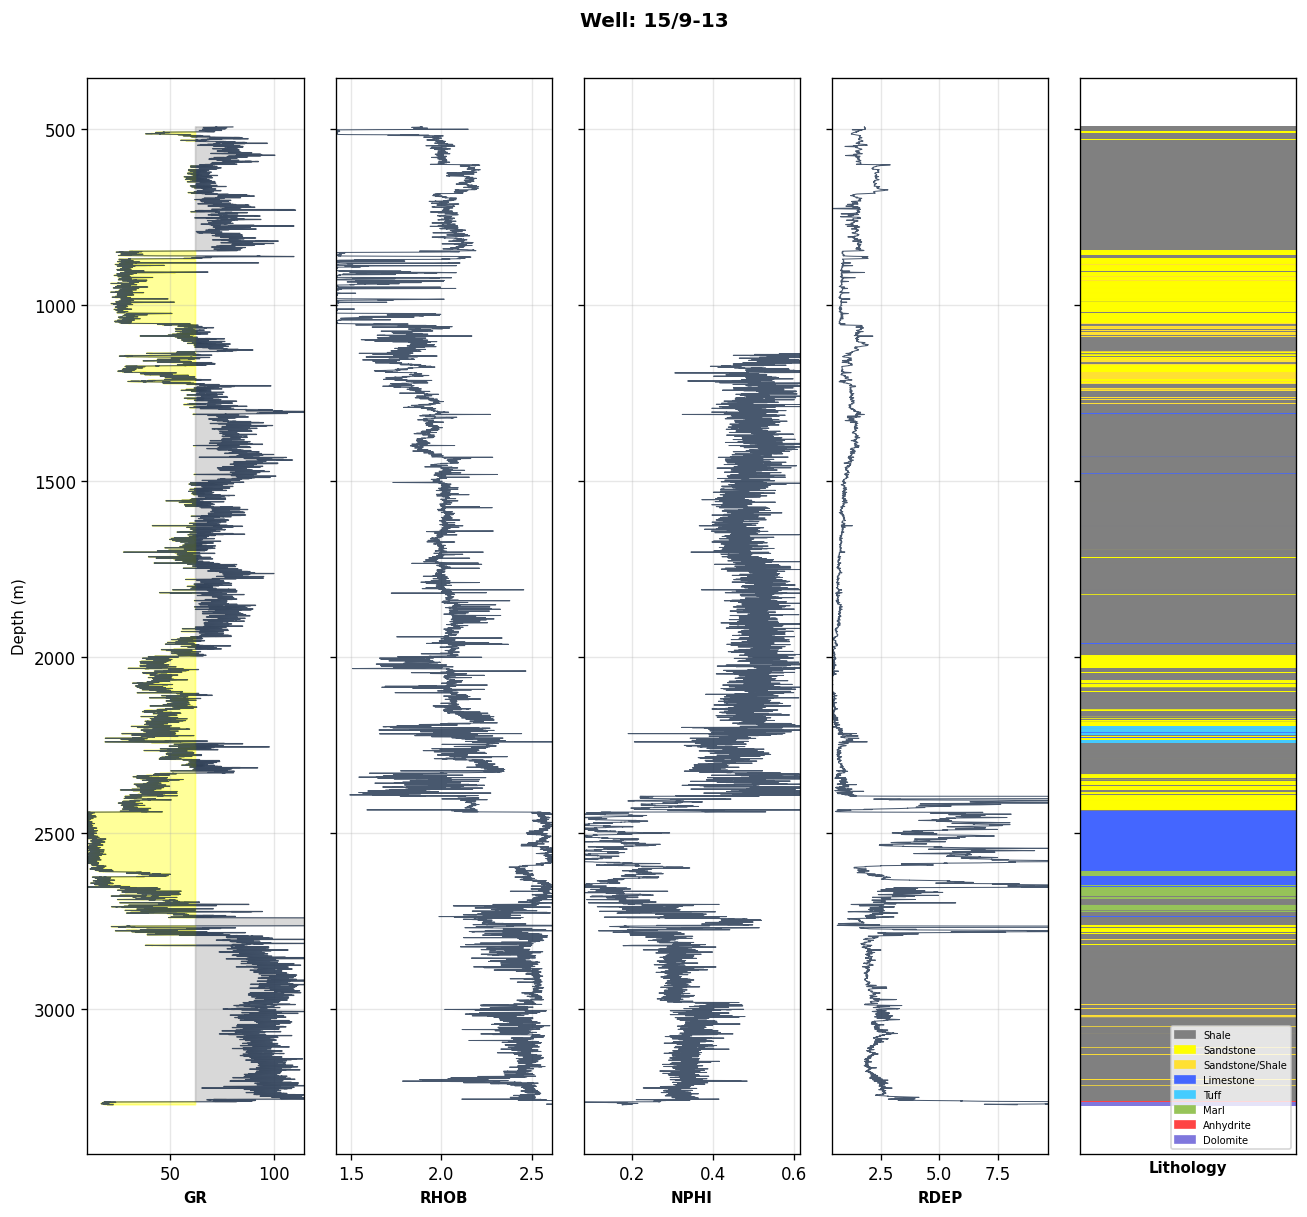

Saved → C:/Users/user/Desktop/SK/Data Science/Personal Projects/Well-Log-Analysis/outputs/figures\well_log_15-9-13.png


In [11]:
def plot_well_logs(df, well_name, depth_col='DEPTH_MD',
                  logs=None, max_depth=None):
    """
    Plot standard well log tracks for a single well.
    Each log gets its own vertical track plotted against depth.
    """
    well_df = df[df['WELL'] == well_name].copy()
    well_df = well_df.sort_values(depth_col)

    if max_depth:
        well_df = well_df[well_df[depth_col] <= max_depth]

    if logs is None:
        logs = ['GR', 'RHOB', 'NPHI', 'RDEP']
        logs = [l for l in logs if l in well_df.columns]

    # Add lithology as the last track
    n_tracks = len(logs) + 1   # +1 for lithology
    fig, axes = plt.subplots(1, n_tracks,
                              figsize=(n_tracks * 2.2, 10),
                              sharey=True)

    fig.suptitle(f"Well: {well_name}", fontsize=12,
                 fontweight='bold', y=1.01)

    depth = well_df[depth_col]

    for i, (ax, log) in enumerate(zip(axes[:-1], logs)):
        values = well_df[log]

        # Clip to 1st–99th percentile for display
        if values.notna().sum() > 10:
            p1  = values.quantile(0.01)
            p99 = values.quantile(0.99)
        else:
            p1, p99 = values.min(), values.max()

        ax.plot(values, depth, linewidth=0.6,
                color='#1A2E4A', alpha=0.8)
        ax.set_xlim(p1, p99)
        ax.set_xlabel(log, fontsize=9, fontweight='bold')
        ax.invert_yaxis()
        ax.grid(True, alpha=0.3)

        if i == 0:
            ax.set_ylabel("Depth (m)", fontsize=9)

        # GR — fill left (shale) green, right (sand) yellow
        if log == 'GR':
            mid = (p1 + p99) / 2
            ax.fill_betweenx(depth, values, mid,
                             where=(values >= mid),
                             color='#808080', alpha=0.3,
                             label='Shale')
            ax.fill_betweenx(depth, values, mid,
                             where=(values < mid),
                             color='#FFFF00', alpha=0.4,
                             label='Sand')

    # Lithology track — colour-coded bars
    ax_lith = axes[-1]
    lith_names = well_df['LITHOLOGY_NAME']

    for j in range(len(well_df) - 1):
        lith  = lith_names.iloc[j]
        color = LITHOLOGY_COLORS.get(lith, '#888888')
        d_top = depth.iloc[j]
        d_bot = depth.iloc[j + 1]
        ax_lith.fill_betweenx([d_top, d_bot], 0, 1,
                               color=color, alpha=0.9)

    ax_lith.set_xlim(0, 1)
    ax_lith.set_xlabel("Lithology", fontsize=9, fontweight='bold')
    ax_lith.set_xticks([])
    ax_lith.invert_yaxis()

    # Legend
    unique_liths = lith_names.dropna().unique()
    legend_patches = [
        plt.Rectangle((0,0), 1, 1,
                      color=LITHOLOGY_COLORS.get(l, '#888'),
                      label=l)
        for l in unique_liths if l in LITHOLOGY_COLORS
    ]
    ax_lith.legend(handles=legend_patches,
                   loc='lower right',
                   fontsize=6, framealpha=0.8)

    plt.tight_layout()
    fname = os.path.join(FIGURES_PATH,
                         f"well_log_{well_name.replace('/','-')}.png")
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved → {fname}")


# Plot the first well
first_well = sorted(df['WELL'].unique())[0]
plot_well_logs(df, well_name=first_well)

This plot is exactly what a petrophysicist would produce professionally. 

Several things stand out immediately.The GR track is working perfectly. The yellow fill marks low-GR zones (clean sand) and grey marks high-GR zones (shale). You can see the alternating sand-shale sequences clearly — those yellow bands correspond exactly to the yellow (Sandstone) and olive (Sandstone/Shale) bands in the lithology track on the right. 

The labels are aligning with the curves, which is the sanity check passing.The deep section below 2500m is geologically interesting. The RDEP resistivity jumps dramatically — from the low flat readings above to high spiky values below. High resistivity in a porous zone means hydrocarbons. That section also shows a large blue (Limestone) band in the lithology track. 

This is the reservoir section of the well.RHOB and NPHI show a lot of noise above 1000m. This is typical — shallow sections often have poor borehole quality (caving, washouts) that corrupts density and neutron readings. The CALI log (caliper) would show the borehole was enlarged in those zones. We will need to handle this in preprocessing.

### ***Correlation between log curves***

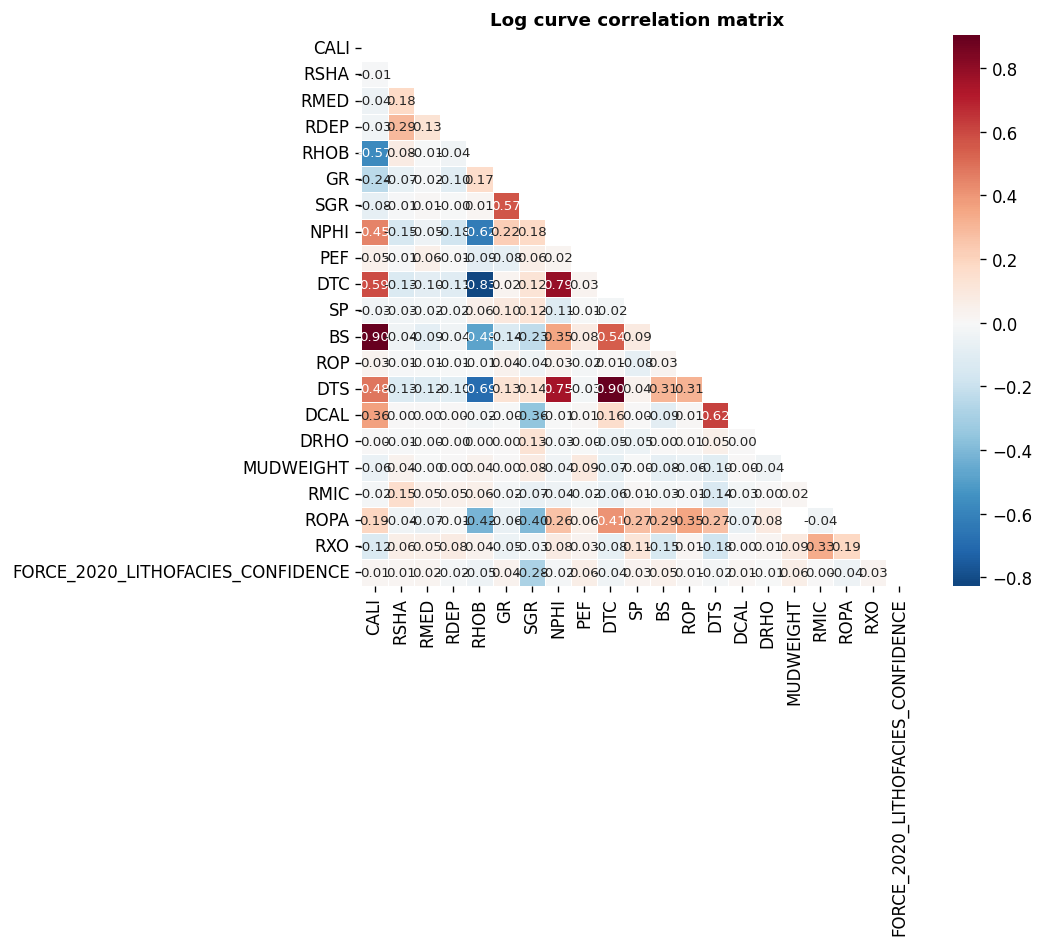

Saved → outputs/figures/log_correlation.png


In [12]:
# Correlation matrix of log curves
corr_cols = [c for c in LOG_COLS if df[c].notna().sum() > 1000]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(corr, mask=mask, annot=True, fmt='.2f',
            cmap='RdBu_r', center=0,
            square=True, linewidths=0.5,
            ax=ax, annot_kws={'size': 8})

ax.set_title("Log curve correlation matrix",
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, "log_correlation.png"),
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved → outputs/figures/log_correlation.png")

The strongest correlations — logs that carry redundant information:


CALI and BS are correlated at −0.90. Both measure borehole diameter — CALI is the caliper tool, BS is bit size. They are essentially the same measurement from different sources. We keep CALI and drop BS.
CALI and DTC correlate at −0.55, and CALI and RHOB at −0.50. This makes geological sense — in washed-out zones where the borehole is enlarged (high CALI), the density and sonic tools are reading fluid rather than rock, giving artificially low RHOB and high DTC. This tells us CALI is a quality control log, not just a feature.


DTC and DTS correlate at 0.75 — compressional and shear sonic travel together as expected. Since DTS has 85% missingness we drop it regardless.
NPHI and DTC correlate at 0.79 — both respond to porosity. High porosity means slow sonic and high neutron porosity. Some redundancy here but both carry independent information for lithology so we keep both.

SGR and GR correlate at 0.57 — spectral gamma ray is just a more detailed version of regular gamma ray. SGR has 94% missingness so it gets dropped regardless.

The important negatives:
RHOB and NPHI correlate at −0.60 and RHOB and DTC at a strong negative value. This is the classic crossplot relationship in petrophysics — denser rocks are less porous, so high RHOB means low NPHI and fast sonic. This opposite behaviour between density and porosity logs is actually useful for lithology discrimination when used together.

What the correlation tells us about feature selection:
Most logs are relatively independent of each other (correlations below 0.3). This is good — it means each log is carrying genuinely different information and we are not feeding the model six versions of the same measurement. The main redundancy to address is CALI/BS, which we resolve by dropping BS.

Highly correlated curves carry redundant information. If RHOB and NPHI are strongly correlated (which they often are), the model might not need both. This informs feature selection in Phase 3.

### ***Log values by lithology class***

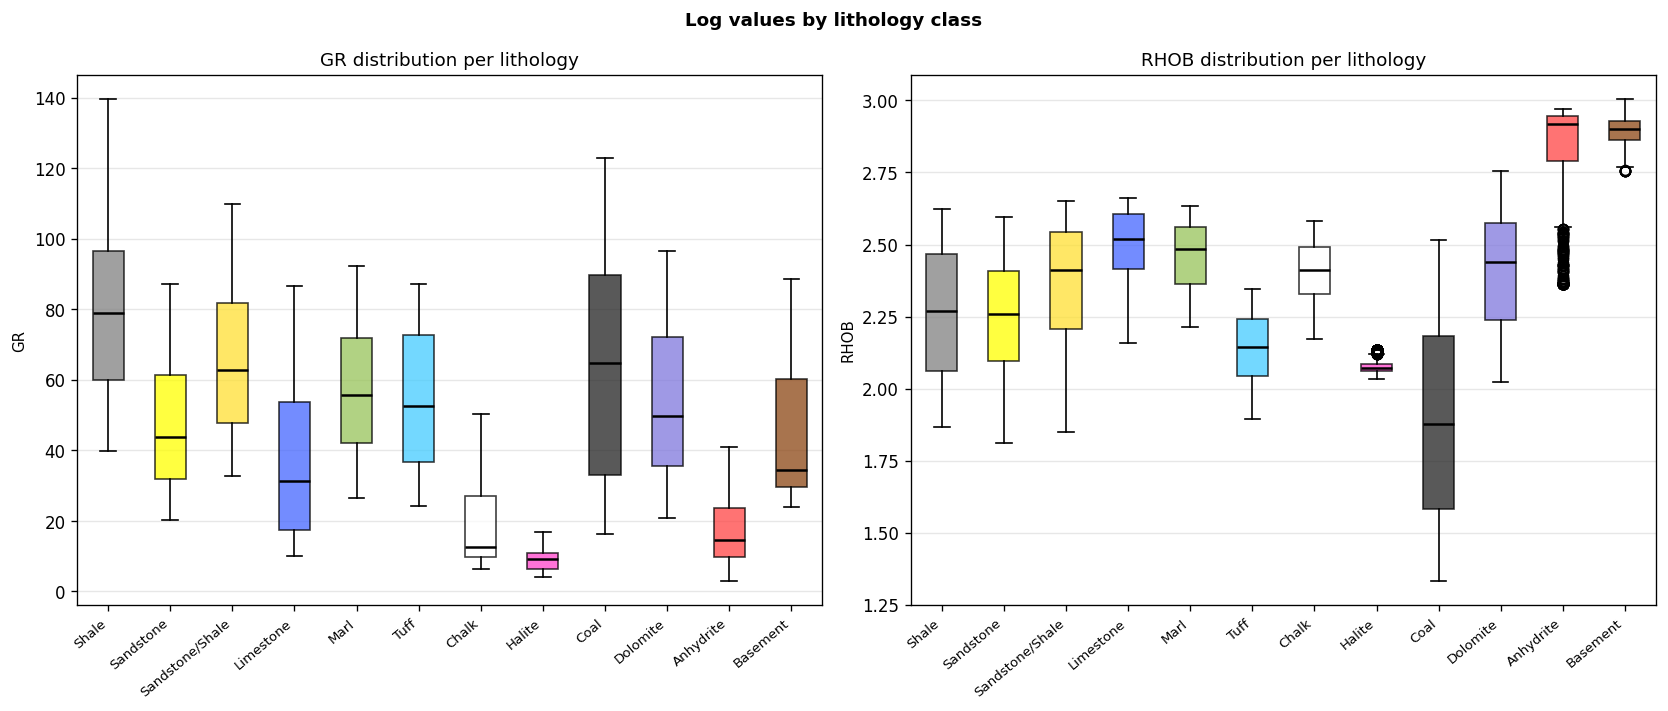

Saved → outputs/figures/logs_by_lithology.png


In [13]:
# Boxplot of GR values per lithology class
# GR is the most discriminative single log for lithology

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Log values by lithology class",
             fontsize=11, fontweight='bold')

for ax, log in zip(axes, ['GR', 'RHOB']):
    if log not in df.columns:
        continue

    data_by_class = []
    labels        = []

    for name in counts.index:
        vals = df[df['LITHOLOGY_NAME'] == name][log].dropna()
        if len(vals) > 10:
            data_by_class.append(vals.clip(
                vals.quantile(0.05),
                vals.quantile(0.95)
            ))
            labels.append(name)

    bp = ax.boxplot(data_by_class, vert=True,
                    patch_artist=True,
                    medianprops=dict(color='black', linewidth=1.5))

    for patch, label in zip(bp['boxes'], labels):
        patch.set_facecolor(LITHOLOGY_COLORS.get(label, '#888'))
        patch.set_alpha(0.75)

    ax.set_xticklabels(labels, rotation=40,
                        ha='right', fontsize=8)
    ax.set_ylabel(log)
    ax.set_title(f"{log} distribution per lithology")
    ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, "logs_by_lithology.png"),
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved → outputs/figures/logs_by_lithology.png")

The GR boxplot is telling a clear story. Several classes are well-separated:
Easily separable from GR alone: Halite (GR ≈ 8, almost zero radioactivity — pure salt has no clay), Chalk (GR ≈ 13, very clean carbonate), Anhydrite (GR ≈ 15, evaporite with no radioactivity), Shale (GR ≈ 78, highest radioactivity of any class).

Hard to separate from GR alone: Sandstone, Sandstone/Shale, Limestone, Marl, and Tuff all overlap significantly in the 30–80 API range. The model will need RHOB, NPHI, and RDEP to pull these apart.

The RHOB boxplot adds separation for the hard classes. Anhydrite and Basement stand out clearly at RHOB above 2.85 g/cc — they are the densest rocks in the section. Coal stands out at the opposite end with RHOB around 1.85 g/cc — coal is the least dense rock type. These distinctive signatures are exactly what the Random Forest and XGBoost will learn to exploit.


## Conclusion
Drop entirely    → SGR, RMIC, DTS, ROPA, DCAL, MUDWEIGHT, RXO (>70% missing)

Keep and impute  → NPHI, PEF, BS, RSHA (moderate missing — impute per-well median)

Keep as-is       → GR, RDEP, RMED, DTC, CALI, RHOB, DRHO, SP

Target column    → FORCE_2020_LITHOFACIES_LITHOLOGY

Rare classes     → consider merging Basement into Shale, Dolomite into Limestone

Class imbalance  → Shale 61.6% — use class_weight='balanced' in both models

Train/test split → hold out 20% of wells entirely (not random rows — wells)
```
